# Braess Paradox with Langroid Driver Agents

**Course:** Multi-Agent Systems  
**Scope:** Reimplementation, validation, and LLM decision-quality analysis

This report reproduces the Braess-paradox examples from the course slides using a Langroid-based traffic simulation. It distinguishes the theoretical traffic outcome from the autonomous decision quality of a local Qwen 2.5 7B model.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "Code").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "Code").exists():
    raise FileNotFoundError("Run this notebook from the project repository.")

RESULT_FILES = {
    "heuristic": PROJECT_ROOT / "results_langroid_tolls_heuristic" / "comparison.csv",
    "llm_checked": PROJECT_ROOT / "results_langroid_7b_toll40_checked" / "comparison.csv",
    "llm_raw": PROJECT_ROOT / "results_langroid_7b_toll40_raw" / "comparison.csv",
}
REPORT_DIR = PROJECT_ROOT / "report_outputs"
REPORT_DIR.mkdir(exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 120)

missing_files = [str(path) for path in RESULT_FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing experiment files: {missing_files}")

print(f"Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")
print(f"Project root: {PROJECT_ROOT}")
print("All required experiment summaries are available.")

Python: 3.12.0
Pandas: 2.3.3
Project root: <project directory>
All required experiment summaries are available.


## 1. Sources, Scope, and Theoretical Reference

**Course sources**

- `Multiagenten_Braess.pdf`: theoretical network, expected values, and toll experiment values.
- `Projektdokumentation.pdf`: implementation rationale and original Qwen/Ollama experiments.
- `Code/braess_assignment_ollama_v3_32b.py` and `32b/toll_20_32b_raw/braess_assignment_ollama_v4_toll.py`: Moodle project code.
- `Code/braess_langroid_simulation.py`: the Langroid reimplementation.

The original network has two routes from Start to Goal:

$$T_A(x) = x/100 + 45, \qquad T_B(x) = 45 + x/100.$$

With 4,000 vehicles, the symmetric allocation is 2,000 vehicles per route, giving $65$ minutes. The extended network adds `A_B`, a two-minute link. If all vehicles use `Start -> A -> B -> Goal`, the expected travel time is:

$$4000/100 + 2 + 4000/100 = 82 \text{ minutes}.$$

The slide deck further reports that an `A_B` toll of $40$ produces the best observed allocation, with an average real travel time near $64.89$ minutes.

## 2. Analysis of the Moodle Code and Its LLM Use

The Moodle implementation is a deterministic traffic engine with an LLM decision layer:

1. Python constructs the network and maintains shared edge loads.
2. Python computes projected direct and remaining travel costs for every available edge.
3. The model receives only the current node, valid edges, and precomputed options as JSON.
4. The model returns one edge name as JSON, for example `{"edge":"S_A"}`.
5. Python validates the response and updates the shared loads after each sequential agent decision.

Therefore, the LLM does **not** solve the traffic assignment problem or calculate the Braess equilibrium. It is a local driver-policy component. The experiment exposes three modes:

| Mode | Meaning | Scientific purpose |
| --- | --- | --- |
| `heuristic` | Python selects the numerical minimum. | Deterministic baseline. |
| `llm_checked` | The LLM proposes an edge; Python corrects valid but non-minimal choices. | Reproduces rational-driver theory while auditing LLM errors. |
| `llm_raw` | Python accepts every valid LLM choice. | Measures the model's autonomous numerical decision quality. |

## 3. Langroid Multi-Agent Reimplementation

The reimplementation in `Code/braess_langroid_simulation.py` replaces direct HTTP prompting with a Langroid `ChatAgent` wrapper around the local Ollama model.

- Each simulated driver receives its own `DriverAgent` / Langroid `ChatAgent` instance.
- Agents do not directly exchange messages.
- The shared edge-load dictionary is the environment through which agents indirectly affect each other.
- Agents are processed sequentially, so every later agent sees congestion created by earlier decisions.
- For toll scenarios, agents minimize decision cost $C = T + \text{toll}$, while final travel time remains only $T$.

This preserves the interaction model shown in the slides while making the LLM agent explicit within a multi-agent framework.

In [2]:
EXPECTED_COLUMNS = {
    "scenario", "toll_ab", "reference_average_time", "simulated_average_time",
    "average_toll", "average_decision_cost", "difference",
    "route_distribution", "edge_loads", "stats",
}

def load_summary(label: str, path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, sep=";")
    missing_columns = EXPECTED_COLUMNS.difference(frame.columns)
    if missing_columns:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing_columns)}")
    frame.insert(0, "decision_mode", label)
    for column in [
        "toll_ab", "reference_average_time", "simulated_average_time",
        "average_toll", "average_decision_cost", "difference",
    ]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    frame["route_distribution"] = frame["route_distribution"].map(json.loads)
    frame["edge_loads"] = frame["edge_loads"].map(json.loads)
    frame["stats"] = frame["stats"].map(json.loads)
    return frame

summaries = pd.concat(
    [load_summary(label, path) for label, path in RESULT_FILES.items()],
    ignore_index=True,
)

english_labels = {
    "heuristic": "Deterministic heuristic",
    "llm_checked": "LLM checked",
    "llm_raw": "LLM raw",
    "original": "Original network",
    "extended": "Extended network (free A-B link)",
    "extended_toll_20": "Extended network (A-B toll 20)",
    "extended_toll_30": "Extended network (A-B toll 30)",
    "extended_toll_40": "Extended network (A-B toll 40)",
    "extended_toll_50": "Extended network (A-B toll 50)",
}

summaries["decision_mode_label"] = summaries["decision_mode"].map(english_labels)
summaries["scenario_label"] = summaries["scenario"].map(english_labels).fillna(summaries["scenario"])
summaries[["decision_mode_label", "scenario_label", "simulated_average_time"]].head()

,decision_mode_label,scenario_label,simulated_average_time
0,Deterministic heuristic,Original network,65.0000
1,Deterministic heuristic,Extended network (free A-B link),82.0000
2,Deterministic heuristic,Extended network (A-B toll 20),69.8676
3,Deterministic heuristic,Extended network (A-B toll 30),66.1275
4,Deterministic heuristic,Extended network (A-B toll 40),64.8876


## 4. Rebuilt Tables and Key Performance Indicators

The table below compares each completed experiment with the theoretical reference from the slides. The deterministic heuristic is included for the complete toll sweep. The LLM campaigns use Qwen 2.5 7B with 500 agents.

In [3]:
report_columns = [
    "decision_mode_label", "scenario_label", "toll_ab", "reference_average_time",
    "simulated_average_time", "difference", "average_toll", "average_decision_cost",
]

kpi_table = (
    summaries[report_columns]
    .rename(columns={
        "decision_mode_label": "Decision mode",
        "scenario_label": "Scenario",
        "toll_ab": "A-B toll",
        "reference_average_time": "Slide reference (min)",
        "simulated_average_time": "Simulated travel time (min)",
        "difference": "Difference from reference (min)",
        "average_toll": "Average toll",
        "average_decision_cost": "Average decision cost",
    })
    .sort_values(["Decision mode", "A-B toll"])
    .reset_index(drop=True)
)

kpi_table.style.format({
    "A-B toll": "{:.0f}",
    "Slide reference (min)": "{:.4f}",
    "Simulated travel time (min)": "{:.4f}",
    "Difference from reference (min)": "{:+.4f}",
    "Average toll": "{:.4f}",
    "Average decision cost": "{:.4f}",
}).background_gradient(subset=["Simulated travel time (min)"], cmap="RdYlGn_r")

,Decision mode,Scenario,A-B toll,Slide reference (min),Simulated travel time (min),Difference from reference (min),Average toll,Average decision cost
0,Deterministic heuristic,Original network,0,65.0000,65.0000,+0.0000,0.0000,65.0000
1,Deterministic heuristic,Extended network (free A-B link),0,82.0000,82.0000,+0.0000,0.0000,82.0000
2,Deterministic heuristic,Extended network (A-B toll 20),20,69.8676,69.8676,+0.0000,11.4800,81.3476
3,Deterministic heuristic,Extended network (A-B toll 30),30,66.1078,66.1275,+0.0197,9.7200,75.8475
4,Deterministic heuristic,Extended network (A-B toll 40),40,64.8948,64.8876,-0.0072,2.9600,67.8476
5,Deterministic heuristic,Extended network (A-B toll 50),50,65.0003,65.0000,-0.0003,0.0000,65.0000
6,LLM checked,Original network,0,65.0000,65.0000,+0.0000,0.0000,65.0000
7,LLM checked,Extended network (free A-B link),0,82.0000,82.0000,+0.0000,0.0000,82.0000
8,LLM checked,Extended network (A-B toll 40),40,64.8948,64.8876,-0.0072,2.9600,67.8476
9,LLM raw,Original network,0,65.0000,78.0573,+13.0573,0.0000,78.0573


## 5. Regenerated Figures with English Annotations

All figures below are generated from the CSV summaries and saved in `report_outputs/`. This makes the report independent of previously generated German-language renders.

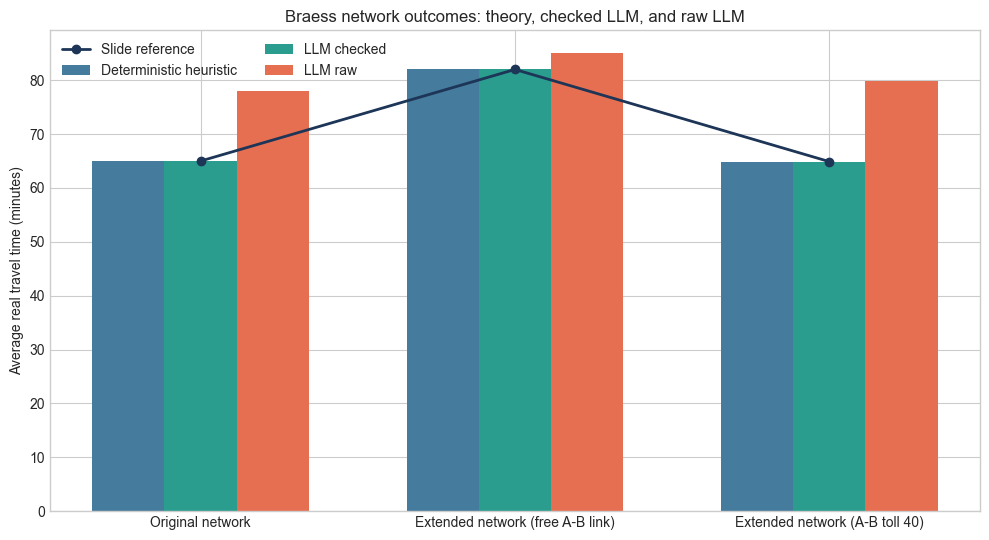

Saved average_travel_time_comparison.png


In [4]:
plot_data = summaries[summaries["scenario"].isin(["original", "extended", "extended_toll_40"])].copy()
scenario_order = ["original", "extended", "extended_toll_40"]
mode_order = ["heuristic", "llm_checked", "llm_raw"]
colors = {"heuristic": "#457b9d", "llm_checked": "#2a9d8f", "llm_raw": "#e76f51"}

fig, ax = plt.subplots(figsize=(10, 5.5))
bar_width = 0.23
positions = range(len(scenario_order))
for offset, mode in enumerate(mode_order):
    subset = plot_data[plot_data["decision_mode"] == mode].set_index("scenario").reindex(scenario_order)
    x_values = [position + (offset - 1) * bar_width for position in positions]
    ax.bar(x_values, subset["simulated_average_time"], width=bar_width, label=english_labels[mode], color=colors[mode])

reference = plot_data.drop_duplicates("scenario").set_index("scenario").reindex(scenario_order)
ax.plot(list(positions), reference["reference_average_time"], color="#1d3557", marker="o", linewidth=2, label="Slide reference")
ax.set_xticks(list(positions), [english_labels[scenario] for scenario in scenario_order])
ax.set_ylabel("Average real travel time (minutes)")
ax.set_title("Braess network outcomes: theory, checked LLM, and raw LLM")
ax.legend(ncol=2)
fig.tight_layout()
travel_time_figure = REPORT_DIR / "average_travel_time_comparison.png"
fig.savefig(travel_time_figure, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {travel_time_figure.name}")

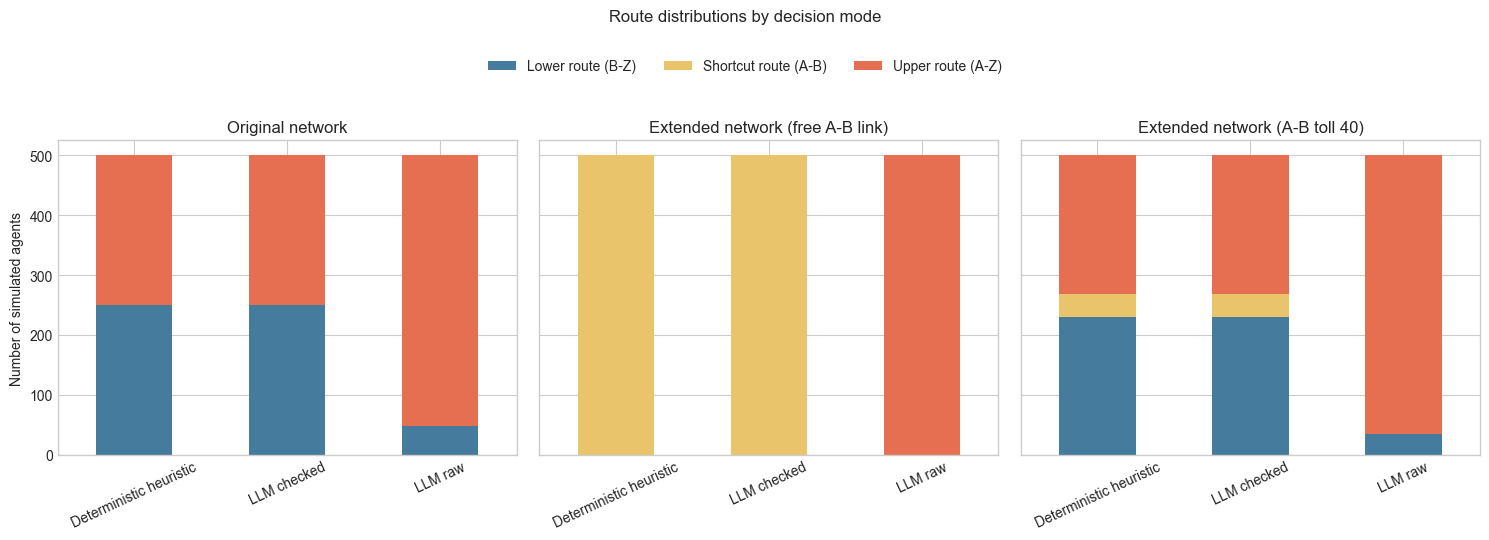

Saved route_distribution_comparison.png


In [5]:
def route_counts(distribution: dict) -> dict[str, int]:
    return {
        "Upper route (A-Z)": distribution.get("Start -> A -> Ziel", 0),
        "Lower route (B-Z)": distribution.get("Start -> B -> Ziel", 0),
        "Shortcut route (A-B)": distribution.get("Start -> A -> B -> Ziel", 0),
    }

route_rows = []
for _, row in plot_data.iterrows():
    for route_label, count in route_counts(row["route_distribution"]).items():
        route_rows.append({
            "Decision mode": row["decision_mode_label"],
            "Scenario": row["scenario_label"],
            "Route": route_label,
            "Agents": count,
        })
route_table = pd.DataFrame(route_rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharey=True)
for axis, scenario in zip(axes, scenario_order):
    subset = route_table[route_table["Scenario"] == english_labels[scenario]]
    pivot = subset.pivot(index="Decision mode", columns="Route", values="Agents").reindex(
        [english_labels[mode] for mode in mode_order]
    ).fillna(0)
    pivot.plot(kind="bar", stacked=True, ax=axis, color=["#457b9d", "#e9c46a", "#e76f51"], legend=False)
    axis.set_title(english_labels[scenario])
    axis.set_xlabel("")
    axis.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Number of simulated agents")
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.suptitle("Route distributions by decision mode", y=1.14)
fig.tight_layout()
route_figure = REPORT_DIR / "route_distribution_comparison.png"
fig.savefig(route_figure, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {route_figure.name}")

## 6. Findings and Interpretation

### Theoretical and checked-agent result

The deterministic heuristic and `llm_checked` runs reproduce the course examples:

- Original network: approximately $65$ minutes with a balanced split.
- Extended network with a free `A_B` link: $82$ minutes, demonstrating the Braess paradox.
- Extended network with toll $40$: $64.8876$ minutes, close to the slide reference of $64.8948$ minutes.

The toll does not make driving faster directly. It changes local incentives, prevents excessive shortcut use, and improves the aggregate allocation.

### Autonomous Qwen 2.5 7B result

The `llm_raw` experiment is deliberately different: it accepts the model's valid JSON selections without numerical correction. The model heavily favors the upper route and frequently selects `A_Z` at node `A` even when `A_B` has a lower estimated total cost. Consequently, it does not reproduce the theoretical equilibrium:

- Original network: $78.0573$ minutes instead of $65$ minutes.
- Extended network: $85.0000$ minutes instead of $82$ minutes.
- Toll $40$: $79.7920$ minutes instead of approximately $64.89$ minutes.

This demonstrates that syntactically valid LLM output is not equivalent to reliable local numerical optimization.

## 7. Limitations and Reproducibility

**Limitations**

- The traffic assignment is sequential and greedy, rather than an iterative Wardrop-equilibrium solver.
- Results in `llm_raw` depend on model version, prompt wording, Ollama runtime settings, and inference hardware.
- `llm_checked` is not a fully autonomous LLM system: Python enforces the numerical optimum after recording the LLM proposal.
- The experiments use a deliberately small network; the framework should be tested on richer networks before drawing practical transport conclusions.

**Reproducibility commands**

```text
python Code/braess_langroid_simulation.py --agents 500 --vehicles 4000 --decision-mode heuristic --output-dir results_langroid_tolls_heuristic
python Code/braess_langroid_simulation.py --agents 500 --vehicles 4000 --decision-mode llm_checked --model qwen2.5:7b --tolls 40 --output-dir results_langroid_7b_toll40_checked
python Code/braess_langroid_simulation.py --agents 500 --vehicles 4000 --decision-mode llm_raw --model qwen2.5:7b --tolls 40 --output-dir results_langroid_7b_toll40_raw
```

Ollama must be available at `http://localhost:11434/v1` and serve `qwen2.5:7b`.

In [6]:
kpi_table.to_csv(REPORT_DIR / "english_kpi_table.csv", index=False)
print("Report deliverables:")
for path in [
    PROJECT_ROOT / "Braess_Langroid_Report.ipynb",
    REPORT_DIR / "english_kpi_table.csv",
    REPORT_DIR / "average_travel_time_comparison.png",
    REPORT_DIR / "route_distribution_comparison.png",
]:
    print(f"- {path.relative_to(PROJECT_ROOT)}: {'ready' if path.exists() else 'created after running plotting cells'}")

try:
    import nbformat
    from nbconvert import HTMLExporter

    notebook_path = PROJECT_ROOT / "Braess_Langroid_Report.ipynb"
    notebook = nbformat.read(notebook_path, as_version=4)
    html, _ = HTMLExporter().from_notebook_node(notebook)
    html_path = REPORT_DIR / "Braess_Langroid_Report.html"
    html_path.write_text(html, encoding="utf-8")
    print(f"- {html_path.relative_to(PROJECT_ROOT)}: ready")
except ImportError:
    print("Install nbconvert to export the notebook as HTML: python -m pip install nbconvert")

Report deliverables:
- Braess_Langroid_Report.ipynb: ready
- report_outputs\english_kpi_table.csv: ready
- report_outputs\average_travel_time_comparison.png: ready
- report_outputs\route_distribution_comparison.png: ready


- report_outputs\Braess_Langroid_Report.html: ready
